# Statistical procedures using `numpy`

A substantial proportion of real world applications in computational modelling require statistical procedures. `numpy` provides a wide variety of efficient statistical functions for you to employ on an array.  This section will explore the (simple and) commonly used functions that you can embed into your models and use for practical statistical analysis.  

<div class="alert alert-block alert-info"><b>Tip:</b> We will explore statistical programming for health data science in a lot more detail using `pandas` and other important libraries.  It is well worth learning `numpy` capabilities, however, as converting from a `np.ndarray` to a `pandas.DataFrame` during a computational procedure can be expensive. </div>

## Imports

In addition to `numpy` we will import `matplotlib` to help us visualise a dataset.  We will learn more about matplotlib in a few weeks time.

In [1]:
import numpy as np

# this is a python plotting library
import matplotlib.pyplot as plt

## Simple data analysis example.

### ED attendance data

We will first use data held in the `minor_illness_ed_attends.csv`.  This is a synthetic time series dataset reporting the number of patients registered at GP surgery who attend ED each week.  The data are standardised to 10k of registered patients.

#### Loading the dataset

Let's first open the data and then construct some summary statistics

In [2]:
file_name = 'data/minor_illness_ed_attends.csv'
ed_data = np.loadtxt(file_name, skiprows=1, delimiter=',')
print(ed_data.shape)

(74,)


Here's a peak the first 5 elements in `ed_data`.

In [3]:
ed_data[:5]

array([2.11927795, 3.49057545, 3.98922908, 2.36860477, 3.24124863])

Let's quickly visualise the time series using `matplotlib`. We will also set the axes labels. 

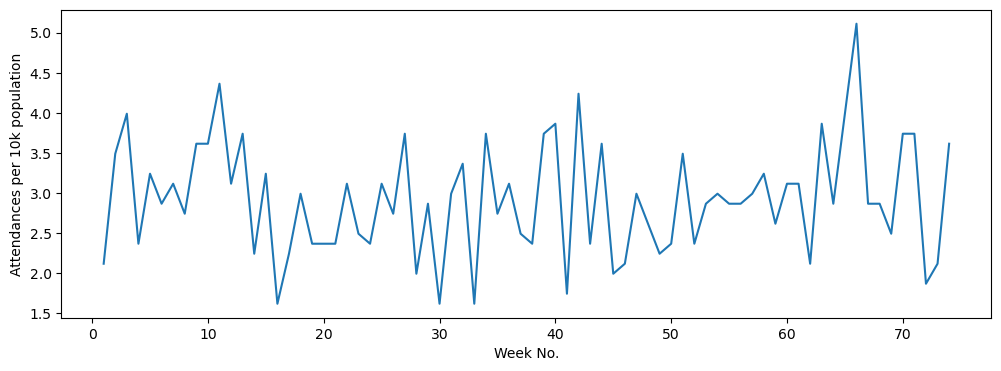

In [4]:
# create figure and axes objects.
fig = plt.figure(figsize=(12,4))
ax = fig.add_subplot()

# ax.plot() returns a list of Line2D objects.
# We don't need to retain that list here.
weeks = np.arange(1, len(ed_data) + 1)
_ = ax.plot(weeks, ed_data)

# axis labels
_ = ax.set_ylabel("Attendances per 10k population")
_ = ax.set_xlabel("Week No.")

# optional: add a vertical line at week 10 (plot inbetween week 10 and 11)
#_ = ax.vlines(x=10.5, ymin=1.5, ymax=5, ls="--", colors='r')

#### Calculate summary statistics

`numpy` makes it easy to calculate means, stdev and other summary statistics of an `ndarray`.  These typically have intuitive names which you can often guess. For example:

In [5]:
print(ed_data.mean())
print(ed_data.std()) # population standard deviation

2.919482262743243
0.7060975938853894


To calculate the sample standard deviation using a divisor of $n - 1$, set `ddof=1` in `np.std()`.


We will write a function that returns summary statistics in a dictionary. Each statistic has a name (a dictionary key), so we can access individual results later.

The function calculates and returns the results; the calling code decides how to display them. We use `np.mean()`, `np.std()`, `np.min()`, `np.max()`, `np.median()` and `np.percentile()`.


In [6]:
def attendance_summary(data):
    """Return summary statistics for a one-dimensional array."""
    lower_quartile = np.percentile(data, 25)
    upper_quartile = np.percentile(data, 75)

    return {
        "mean": np.mean(data),
        "std": np.std(data, ddof=1),
        "min": np.min(data),
        "max": np.max(data),
        "median": np.median(data),
        "iqr": upper_quartile - lower_quartile,
        "n": len(data),
    }

In [7]:
summary = attendance_summary(ed_data)

print("Dataset: ED")
for statistic in ["mean", "std", "min", "max", "median", "iqr"]:
    print(f"{statistic}:\t{summary[statistic]:.2f}")
print(f"n:\t{summary['n']}")


Dataset: ED
mean:	2.92
std:	0.71
min:	1.62
max:	5.11
median:	2.87
iqr:	1.09
n:	74


In [8]:
# Calculate the frequencies and bin edges, then display the results.
frequencies, bin_edges = np.histogram(ed_data)

print("Lower edge\tFrequency")
for i in range(len(frequencies)):
    print(f"{bin_edges[i]:.2f}\t\t{frequencies[i]}")

Lower edge	Frequency
1.62		5
1.97		9
2.32		14
2.67		16
3.02		11
3.37		6
3.71		10
4.06		2
4.41		0
4.76		1


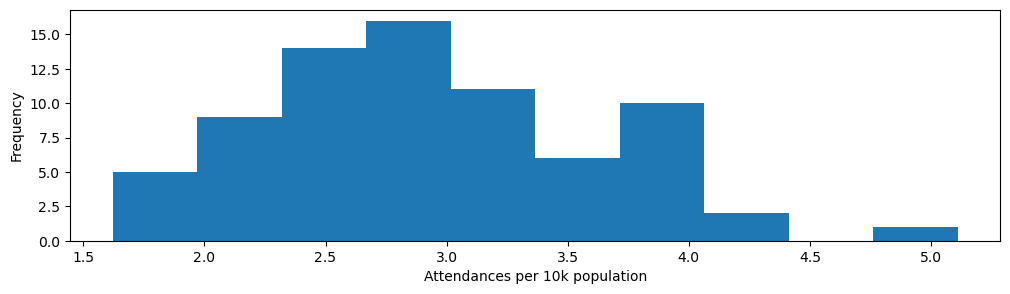

In [9]:
# plot as a histogram
fig = plt.figure(figsize=(12,3))
ax = fig.add_subplot()

# use the hist method pass in all the data
_ = ax.hist(ed_data)

# axis labels
_ = ax.set_ylabel("Frequency")
_ = ax.set_xlabel("Attendances per 10k population")

We can reuse `attendance_summary()` with different slices of an array. Each call returns a dictionary that we can store and use later.

Let's assume GP surgeries opened over weekends after the first 10 weeks. We can compare descriptive statistics before and after this intervention.


In [10]:
week = 10  # number of weeks before the intervention
before = attendance_summary(ed_data[:week])
after = attendance_summary(ed_data[week:])

In [11]:
print("Statistic\tBefore\tAfter")
for statistic in before.keys():
    print(f"{statistic}\t\t{before[statistic]:.2f}\t{after[statistic]:.2f}")

Statistic	Before	After
mean		3.12	2.89
std		0.59	0.73
min		2.12	1.62
max		3.99	5.11
median		3.18	2.87
iqr		0.81	0.90
n		10.00	64.00


## Statistical procedures and n-dimensional arrays

Generating statistics for matrices and n-dimensional arrays works in a similar manner to vectors.  We can also go a bit further and calculate statistics across axes in the array; for example, rows and columns in a matrix. To do this you need to specify an integer **axis** in the call to the statistical function e.g. `mean(axis=0)`

### Example 1: mean of matrix columns and rows

Given `matrix` calculate the mean of the columns and rows.  We will first generate these manually using slices so that you can see it is working correctly.

In [12]:
matrix = np.array([[7.7, 4.3, 8.5],
                   [6.9, 0.9, 9.7],
                   [7.6, 7.8, 1.2]])

To calculate the mean of the first column we need to slice all rows and the column at index 0. As a reminder we would do the following:

> Try changing the value of 0 to 1 or 2 to get the other columns.

In [13]:
matrix[:,0]

array([7.7, 6.9, 7.6])

This is a vector and hence calculating the mean is as we have already seen 

> here I also call `.round(1)` to also limit displayed the result to 1 decimal place.  You could also use a format str.

In [14]:
matrix[:,0].mean().round(1)

np.float64(7.4)

In [15]:
print(matrix[:,1].mean().round(1))
print(matrix[:,2].mean().round(1))

4.3
6.5


This is a common operation so we can instead specify an axis.  In a matrix we use axis 0 for columns and 1 for rows. In other words `axis=0` collapses the rows and you get one result per column.

In [16]:
matrix.mean(axis=0).round(1)

array([7.4, 4.3, 6.5])

In [17]:
matrix.mean(axis=1).round(1)

array([6.8, 5.8, 5.5])

### Example 2: Statistical operations on a larger dataset

We will use the preprocessed Wisconsin breast cancer dataset supplied in `data/wisconsin.csv`. The file has a header row containing feature names, followed by numeric feature data. Take a look at the dataset before running the code below.

We will load the columns header separately, then skip that row it when loading the numeric data. 

In [18]:
file_name = "data/wisconsin.csv"

# only include column index 3 to the end
indexes_to_include = np.arange(3, 33)

header_names = np.genfromtxt(
    fname=file_name, 
    usecols=indexes_to_include, 
    delimiter=",", 
    dtype=str, max_rows=1
)

wisconsin = np.genfromtxt(
    fname=file_name, 
    skip_header=1, 
    usecols=indexes_to_include, 
    delimiter=','
)

print(wisconsin.shape)
print(header_names[:4])

(569, 30)
['radius_mean' 'texture_mean' 'perimeter_mean' 'area_mean']


We can now summarise each feature. The function below uses `axis=0` to calculate statistics for each column.

It returns a dictionary in which each value is an array containing one result per feature. We display the results separately.


In [19]:
def feature_summary(data):
    """Return summary statistics for each column in a two-dimensional array."""
    lower_quartiles = np.percentile(data, 25, axis=0)
    upper_quartiles = np.percentile(data, 75, axis=0)

    return {
        "mean": np.mean(data, axis=0),
        "std": np.std(data, ddof=1, axis=0),
        "median": np.median(data, axis=0),
        "iqr": upper_quartiles - lower_quartiles,
        "range": np.max(data, axis=0) - np.min(data, axis=0),
    }

In [20]:
def display_summary(headers, summary):
    """Display a formatted table of summary statistics"""

    # these help with the summary layout.
    max_header_padding_len = max(len(x) for x in headers)
    header_padding = ''.rjust(max_header_padding_len)
    
    header_row = f"{header_padding}\tMean\tStd\tMedian\tIQR\tRange"
    print(header_row)
    line = ['-'] * int(len(header_row) * 1.3)
    print(''.join(line))
    for i in range(len(headers)):
        row_padding_len = max_header_padding_len - len(headers[i])
        row_padding = ''.rjust(row_padding_len)
        field = f'{headers[i]}{row_padding}\t' \
                + f"{summary['mean'][i]:.2f}\t" \
                + f"{summary['std'][i]:.2f}\t" \
                + f"{summary['median'][i]:.2f}\t" \
                + f"{summary['iqr'][i]:.2f}\t" \
                + f"{summary['range'][i]:.2f}"
        print(field) 

In [21]:
# get the summary dictionary
summary = feature_summary(wisconsin)

print("Wisconsin Breast Cancer Dataset\n")

# display results formatted as ASCII table.
display_summary(header_names, summary)

Wisconsin Breast Cancer Dataset

                       	Mean	Std	Median	IQR	Range
---------------------------------------------------------------
radius_mean            	14.13	3.52	13.37	4.08	21.13
texture_mean           	19.29	4.30	18.84	5.63	29.57
perimeter_mean         	91.97	24.30	86.24	28.93	144.71
area_mean              	654.89	351.91	551.10	362.40	2357.50
smoothness_mean        	0.10	0.01	0.10	0.02	0.11
compactness_mean       	0.10	0.05	0.09	0.07	0.33
concavity_mean         	0.09	0.08	0.06	0.10	0.43
concave points_mean    	0.05	0.04	0.03	0.05	0.20
symmetry_mean          	0.18	0.03	0.18	0.03	0.20
fractal_dimension_mean 	0.06	0.01	0.06	0.01	0.05
radius_se              	0.41	0.28	0.32	0.25	2.76
texture_se             	1.22	0.55	1.11	0.64	4.52
perimeter_se           	2.87	2.02	2.29	1.75	21.22
area_se                	40.34	45.49	24.53	27.34	535.40
smoothness_se          	0.01	0.00	0.01	0.00	0.03
compactness_se         	0.03	0.02	0.02	0.02	0.13
concavity_se           	0.03	0.03	0.03	